# 3. Transits and binning

Two knobs control the precision of a simulated observation.

- `n_transits`: how many transits are co-added. The noise tables store a
  single-transit depth uncertainty per detector channel; `observe()` scales it
  by 1/√N.
- `R`: the resolving power the model and noise are binned to. Coarser bins
  average more channels, so each bin is more precise and resolves less.

This notebook shows both, then opens the `lazuli_exo.binning` module that
implements them, including the instrument response and the two resolution
limits.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    plt.style.use("gks")
except OSError:
    pass

import lazuli_exo

print("lazuli_exo", lazuli_exo.__file__)

lazuli_exo /Users/gudmundurstefansson/Dropbox/mypylib/notebooks/GIT/lazuli-exo/src/lazuli_exo/__init__.py


## √N scaling

`depth_err` is the single-transit error divided by √N. Nothing else changes; the
model `depth` is identical.

In [2]:
PLANET = "WASP-39 b"
n_grid = np.array([1, 2, 5, 10, 20, 50])

obs1 = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=100)
errs = []
for n in n_grid:
    o = lazuli_exo.observe(PLANET, scenario="clear", n_transits=int(n), R=100)
    errs.append(np.median(o.depth_err))
    assert np.array_equal(o.depth, obs1.depth), "model must not change with N"

errs = np.array(errs)
ratio = errs[0] / errs

print(f"{'N':>4s}{'median sigma (ppm)':>22s}{'sigma_1/sigma_N':>18s}"
      f"{'sqrt(N)':>10s}")
for n, e, r in zip(n_grid, errs, ratio):
    print(f"{n:4d}{e * 1e6:22.2f}{r:18.4f}{np.sqrt(n):10.4f}")

assert np.allclose(ratio, np.sqrt(n_grid))
print("\nOK: errors scale exactly as 1/sqrt(N).")

   N    median sigma (ppm)   sigma_1/sigma_N   sqrt(N)
   1                106.72            1.0000    1.0000
   2                 75.46            1.4142    1.4142
   5                 47.73            2.2361    2.2361
  10                 33.75            3.1623    3.1623
  20                 23.86            4.4721    4.4721
  50                 15.09            7.0711    7.0711

OK: errors scale exactly as 1/sqrt(N).


The statistic is linear in 1/σ, so the template S/N inherits the same scaling.
This is the clearest illustration of what the model leaves out: there is no
per-transit systematics term and no red-noise floor, so the curve never
flattens.

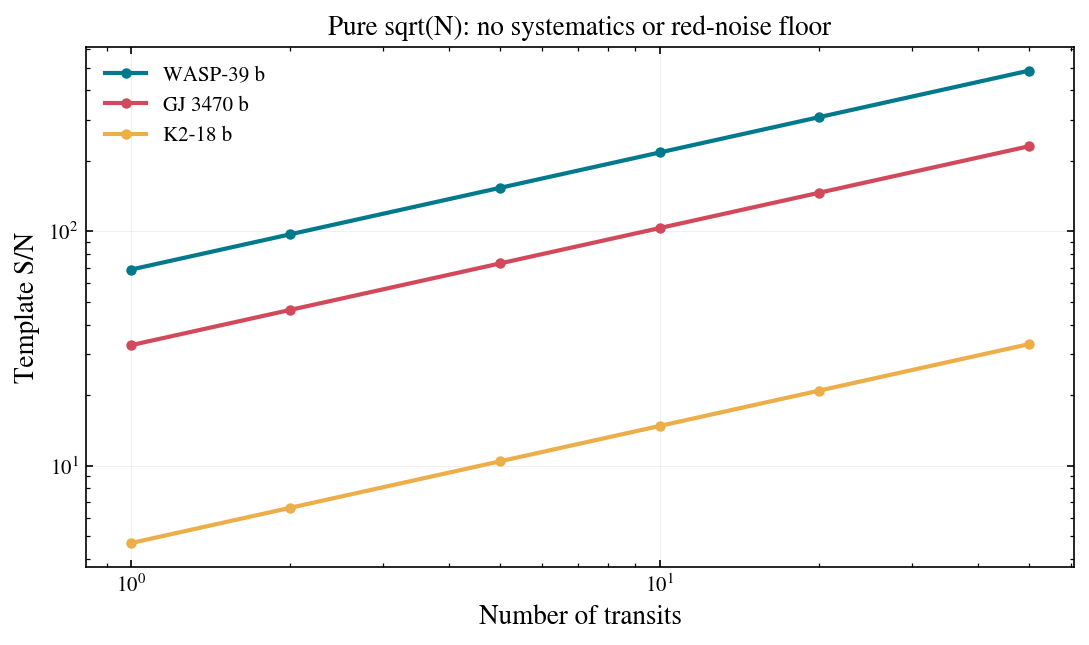

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))

for planet in ["WASP-39 b", "GJ 3470 b", "K2-18 b"]:
    snr = [lazuli_exo.observe(planet, scenario="clear", n_transits=int(n))
           .detect()["template_snr_diagonal"] for n in n_grid]
    ax.plot(n_grid, snr, "o-", ms=4, label=planet)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of transits")
ax.set_ylabel("Template S/N")
ax.set_title("Pure sqrt(N): no systematics or red-noise floor")
ax.legend(frameon=False)
plt.show()

## What `R` does to the error bar

`obs.plot_noise(ax=ax)` overlays the per-bin error of several binnings. Coarser
bins combine more channels in inverse variance, so the whole curve drops as the
bins widen; the sawtooth at high `R` is real and comes from bins being whole
numbers of pixels. R = 200 also triggers a `UserWarning` about the instrument
resolving power, which the section on resolution limits below explains; the
warnings are left visible in this notebook.

/var/folders/0t/mnkwbhz90sv50nypf2rcl8cr0000gp/T/ipykernel_84088/2291477036.py:3: UserWarning: requested R=200 exceeds the instrument resolving power (R_instr = 101-369 over the binned range); bins narrower than a resolution element are correlated by the LSF
  o = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=R)


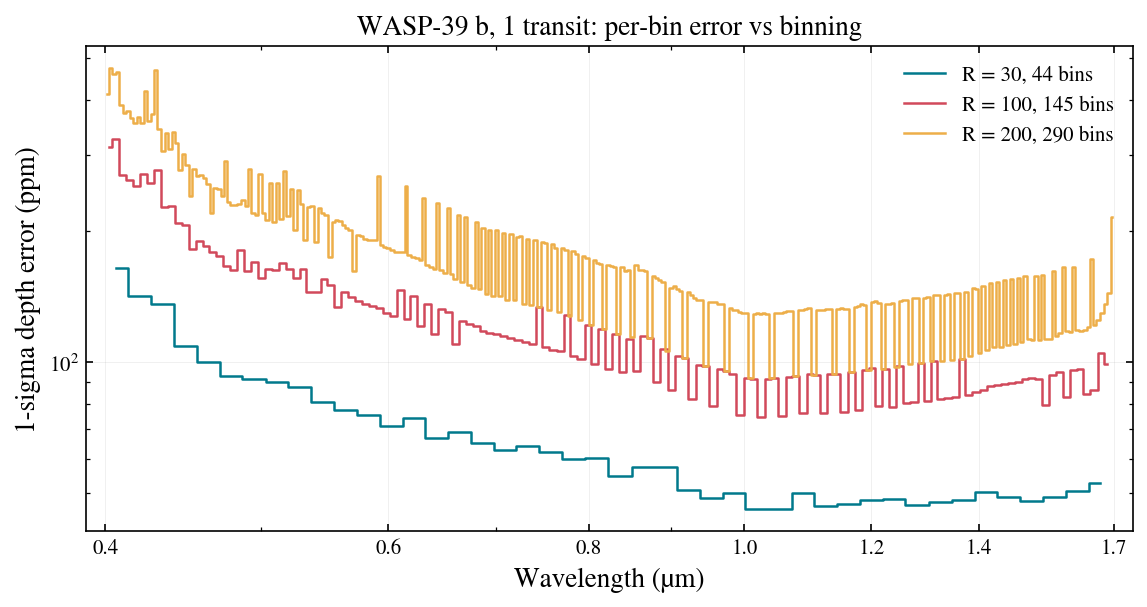

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for R in [30, 100, 200]:
    o = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=R)
    o.plot_noise(ax=ax, label=f"R = {R}, {o.wavelength.size} bins")
ax.set_title(f"{PLANET}, 1 transit: per-bin error vs binning")
plt.show()

## Choosing `R`

Coarser bins mean fewer, more precise points. The total template S/N is roughly
preserved as long as the bins still resolve the features, and only degrades once
a bin is wide enough to average a band's peak against its continuum.

Above R ≈ 100 the cells below emit the same `UserWarning`. That is the first of
two resolution limits, explained further down: the requested bins are narrower
than the spectrograph's resolution element, so neighbouring bins are correlated
by the line-spread function and the error bars are no longer independent.

In [5]:
R_grid = [30, 50, 100, 150, 200]

print(f"{'R':>5s}{'bins':>7s}{'median sigma (ppm)':>22s}"
      f"{'template S/N':>15s}")
for R in R_grid:
    o = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=R)
    print(f"{R:5d}{o.wavelength.size:7d}{np.median(o.depth_err) * 1e6:22.2f}"
          f"{o.detect()['template_snr_diagonal']:15.1f}")

    R   bins    median sigma (ppm)   template S/N
   30     44                 58.58           65.9
   50     73                 74.87           67.8
  100    145                106.72           68.6
  150    217                135.93           68.9
  200    290                156.10           69.0


/var/folders/0t/mnkwbhz90sv50nypf2rcl8cr0000gp/T/ipykernel_84088/1743028282.py:6: UserWarning: requested R=150 exceeds the instrument resolving power (R_instr = 101-369 over the binned range); bins narrower than a resolution element are correlated by the LSF
  o = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=R)
/var/folders/0t/mnkwbhz90sv50nypf2rcl8cr0000gp/T/ipykernel_84088/1743028282.py:6: UserWarning: requested R=200 exceeds the instrument resolving power (R_instr = 101-369 over the binned range); bins narrower than a resolution element are correlated by the LSF
  o = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=R)


/var/folders/0t/mnkwbhz90sv50nypf2rcl8cr0000gp/T/ipykernel_84088/639674813.py:4: UserWarning: requested R=200 exceeds the instrument resolving power (R_instr = 101-369 over the binned range); bins narrower than a resolution element are correlated by the LSF
  o = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=R)


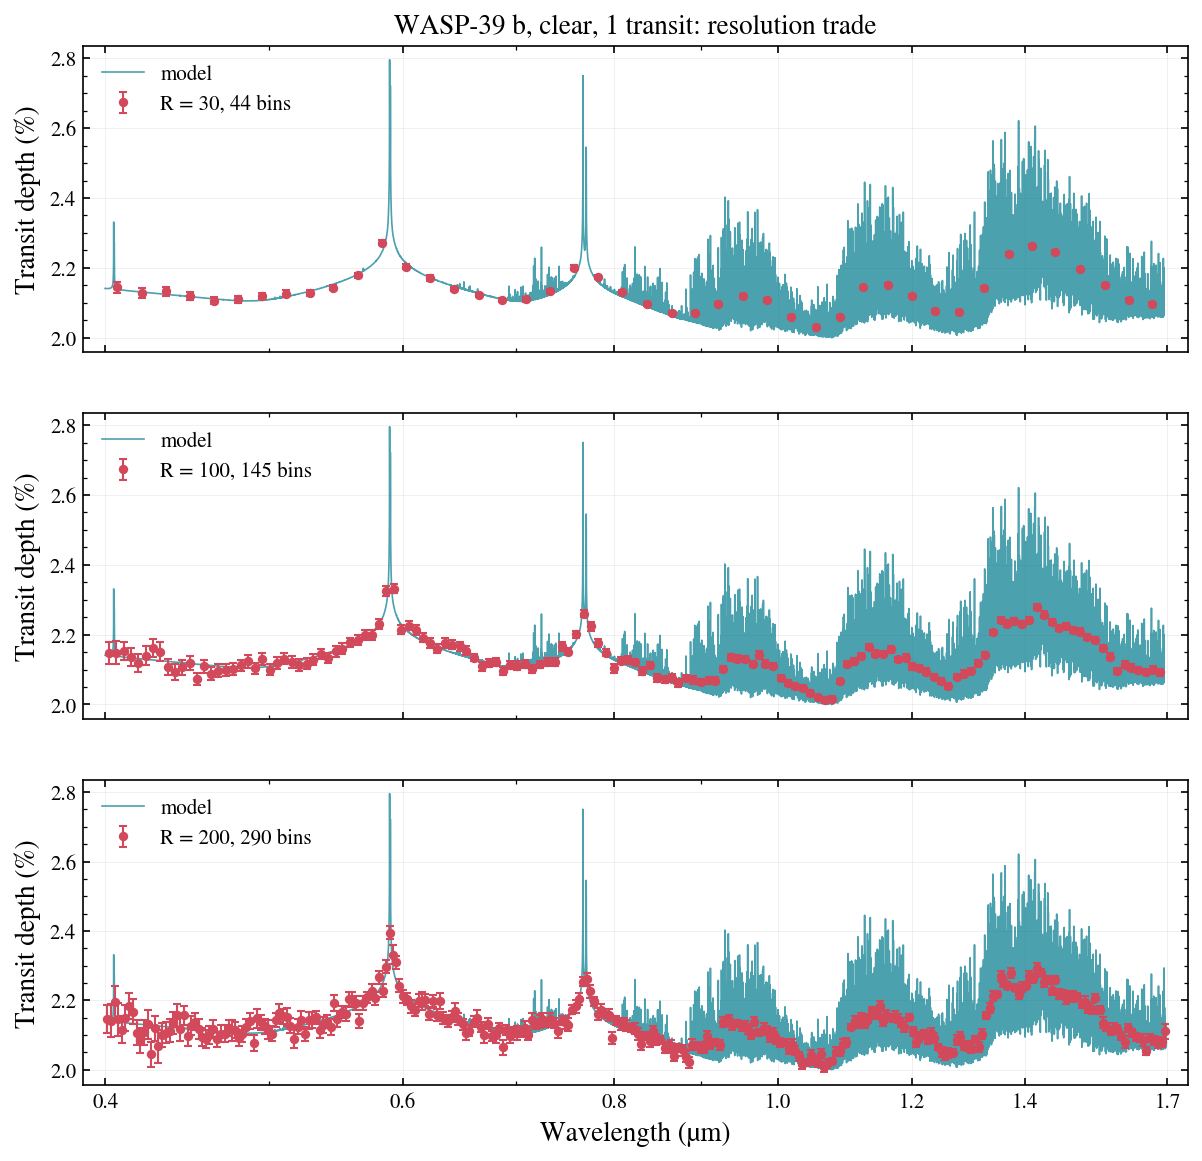

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(9.5, 9), sharex=True)

for ax, R in zip(axes, [30, 100, 200]):
    o = lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=R)
    o.plot(ax=ax, seed=0, label=f"R = {R}, {o.wavelength.size} bins")
    ax.legend(frameon=False, loc="upper left")
for ax in axes[:-1]:
    ax.set_xlabel("")
axes[0].set_title(f"{PLANET}, clear, 1 transit: resolution trade")
plt.show()

## The binning module

`observe()` builds its grid with `lazuli_exo.binning`. The edges are geometric,
so every bin has the same fractional width 1 + 1/R, and only complete bins are
kept, so the grid can stop up to one bin short of the requested `wl_max`.

In [7]:
from lazuli_exo import binning

edges = binning.constant_R_edges(0.40, 1.70, 100)
centers = binning.bin_centers(edges)

print(f"{len(centers)} complete bins over [{edges[0]:.4f}, "
      f"{edges[-1]:.4f}] um")
print(f"edge ratio: {edges[1] / edges[0]:.6f}  "
      f"(expected {1 + 1 / 100:.6f})")

frac = np.diff(edges) / centers
print(f"fractional width: constant at {frac.mean():.6f} "
      f"(spread {frac.std():.2e})")
print(f"shortfall below 1.70 um: {(1.70 - edges[-1]) * 1e3:.2f} nm "
      f"(< one bin width of {np.diff(edges)[-1] * 1e3:.2f} nm)")

# bin_centers is the geometric mean of the edges
assert np.allclose(centers, np.sqrt(edges[:-1] * edges[1:]))

145 complete bins over [0.4000, 1.6930] um
edge ratio: 1.010000  (expected 1.010000)
fractional width: constant at 0.009950 (spread 9.47e-17)
shortfall below 1.70 um: 6.99 nm (< one bin width of 16.76 nm)


## The instrument response

`observe()` does not simply average the model into bins. `bin_observation`
snaps the constant-R edges to detector channel edges, convolves the stellar
photon flux and the in-transit flux with the Gaussian line-spread function
(sigma 1.15 px), integrates per pixel, and then combines the per-channel depths
with the channel 1/σ² weights. `obs.meta["instrument_response"]` records what
was done.

In [8]:
from lazuli_exo import tables

tdir = tables.resolve_tables_dir(None)
wl_n, err_n, meta_n = tables.load_noise(tdir, PLANET)

print(obs1.meta["instrument_response"])
print()
R_inst = binning.R_instr(wl_n)
print(f"{wl_n.size} native noise channels over [{wl_n.min():.4f}, {wl_n.max():.4f}] um")
print(f"instrument resolving power (2.3 px per element): "
      f"{R_inst[0]:.0f} at {wl_n[0]:.2f} um, "
      f"minimum {R_inst.min():.0f} at {wl_n[R_inst.argmin()]:.2f} um, "
      f"{R_inst[-1]:.0f} at {wl_n[-1]:.2f} um")

# the LSF smooths the model: a plain bin average differs from the instrument
# response in the line cores, where the model has structure narrower than a pixel
edges100 = binning.snap_edges_to_channels(
    binning.constant_R_edges(wl_n.min(), wl_n.max(), 100), wl_n)
plain = binning.bin_model(obs1.model_wavelength, obs1.model_depth, edges100)
d = (plain - obs1.depth) * 1e6
i = np.argmax(np.abs(d))
print(f"\nplain bin average minus instrument response: median |diff| {np.median(np.abs(d)):.1f} ppm, "
      f"largest {d[i]:+.0f} ppm at {obs1.wavelength[i]:.3f} um")

{'lsf_sigma_px': 1.15, 'resolution_px': 2.3, 'R_instr_min': 100.59561419775318, 'R_instr_max': 368.7306328000536, 'photon_weighting': 'star table R=10000', 'edges_snapped': True}

525 native noise channels over [0.4000, 1.6993] um
instrument resolving power (2.3 px per element): 369 at 0.40 um, minimum 101 at 1.02 um, 165 at 1.70 um

plain bin average minus instrument response: median |diff| 5.7 ppm, largest +255 ppm at 0.768 um


## The two resolution limits

Both are set where the dispersion makes the pixels coarsest in resolving
power, which for Lazuli is near 1.0 µm rather than at either end of the band
(the cell above printed the numbers).

1. The instrument resolving power (minimum about 100). Above it the call still
   runs but warns: bins narrower than a resolution element are correlated by
   the line-spread function.
2. The native channel sampling (minimum about 230, one pixel per bin). Above
   it the call raises a `ValueError`.

In [9]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=150)
print(f"R=150: {caught[0].category.__name__}: {caught[0].message}\n")

try:
    lazuli_exo.observe(PLANET, scenario="clear", n_transits=1, R=400)
except ValueError as exc:
    print(f"R=400: ValueError: {exc}")
else:
    raise AssertionError("expected a ValueError")

R=150: UserWarning: requested R=150 exceeds the instrument resolving power (R_instr = 101-369 over the binned range); bins narrower than a resolution element are correlated by the LSF

R=400: ValueError: requested R exceeds the native noise sampling (bins narrower than one channel; R_px >= 231)


`n_transits` is validated too.

In [10]:
try:
    lazuli_exo.observe(PLANET, n_transits=0)
except ValueError as exc:
    print(f"ValueError: {exc}")
else:
    raise AssertionError("expected a ValueError")

ValueError: n_transits must be >= 1


## How many transits to reach a target S/N

A practical use of the √N scaling is to invert it. The statistic is exactly
linear in √N, so the number of transits needed to reach a target follows in
closed form from a single-transit run.

<div class="alert alert-warning">

These are not observing-time forecasts. The statistic is not a calibrated
significance, and the noise model has no systematics floor, so the real number of
transits would be larger by an amount this model cannot tell you.

</div>

In [11]:
TARGET_SNR = 100.0

rows = []
with warnings.catch_warnings():
    # one bright host warns about residual detector saturation;
    # see notebook 05 for what that means
    warnings.simplefilter("ignore", UserWarning)
    for p in lazuli_exo.list_planets():
        snr1 = lazuli_exo.observe(
            p, scenario="clear",
            n_transits=1).detect()["template_snr_diagonal"]
        rows.append((p, snr1, int(np.ceil((TARGET_SNR / snr1) ** 2))))

rows.sort(key=lambda r: r[2])
print(f"transits for template S/N = {TARGET_SNR:.0f}, clear scenario\n")
print(f"{'planet':14s}{'S/N (1 transit)':>17s}{'N needed':>11s}")
for p, snr1, n in rows:
    print(f"{p:14s}{snr1:17.2f}{n:11d}")

transits for template S/N = 100, clear scenario

planet          S/N (1 transit)   N needed
HD 209458 b              111.61          1
WASP-107 b               143.06          1
HD 189733 b               74.23          2
WASP-39 b                 68.65          3
WASP-121 b                49.61          5
GJ 3470 b                 32.65         10
GJ 1214 b                 30.96         11
WASP-12 b                 27.55         14
WASP-96 b                 20.62         24
HAT-P-11 b                17.16         34
TOI-270 d                 10.76         87
TRAPPIST-1 e               9.62        109
LHS 1140 b                 7.21        193
K2-18 b                    4.67        459


In [12]:
# verify the closed form against an actual re-run for one target
p, snr1, n = rows[len(rows) // 2]
actual = lazuli_exo.observe(p, scenario="clear",
                            n_transits=n).detect()["template_snr_diagonal"]
print(f"{p}: predicted N={n} -> S/N {snr1 * np.sqrt(n):.3f}, "
      f"actual {actual:.3f}")
assert np.isclose(snr1 * np.sqrt(n), actual)
print("OK: the closed form is exact.")

WASP-12 b: predicted N=14 -> S/N 103.084, actual 103.084
OK: the closed form is exact.


## Summary

- `n_transits` scales `depth_err` by exactly 1/√N and nothing else; the model
  `depth` is untouched.
- Template S/N therefore grows as √N without limit. The model has no systematics
  or red-noise floor, which is its main unrealism here.
- `R` sets a geometric bin grid snapped to whole pixels; the model goes through
  the line-spread function before binning, and channels combine in inverse
  variance.
- Above the instrument resolving power (about 100, set near 1.0 µm) you get a
  warning; above the pixel sampling (about 230) you get a `ValueError`.

Next: [light curves](04_light_curves.ipynb), the time domain.